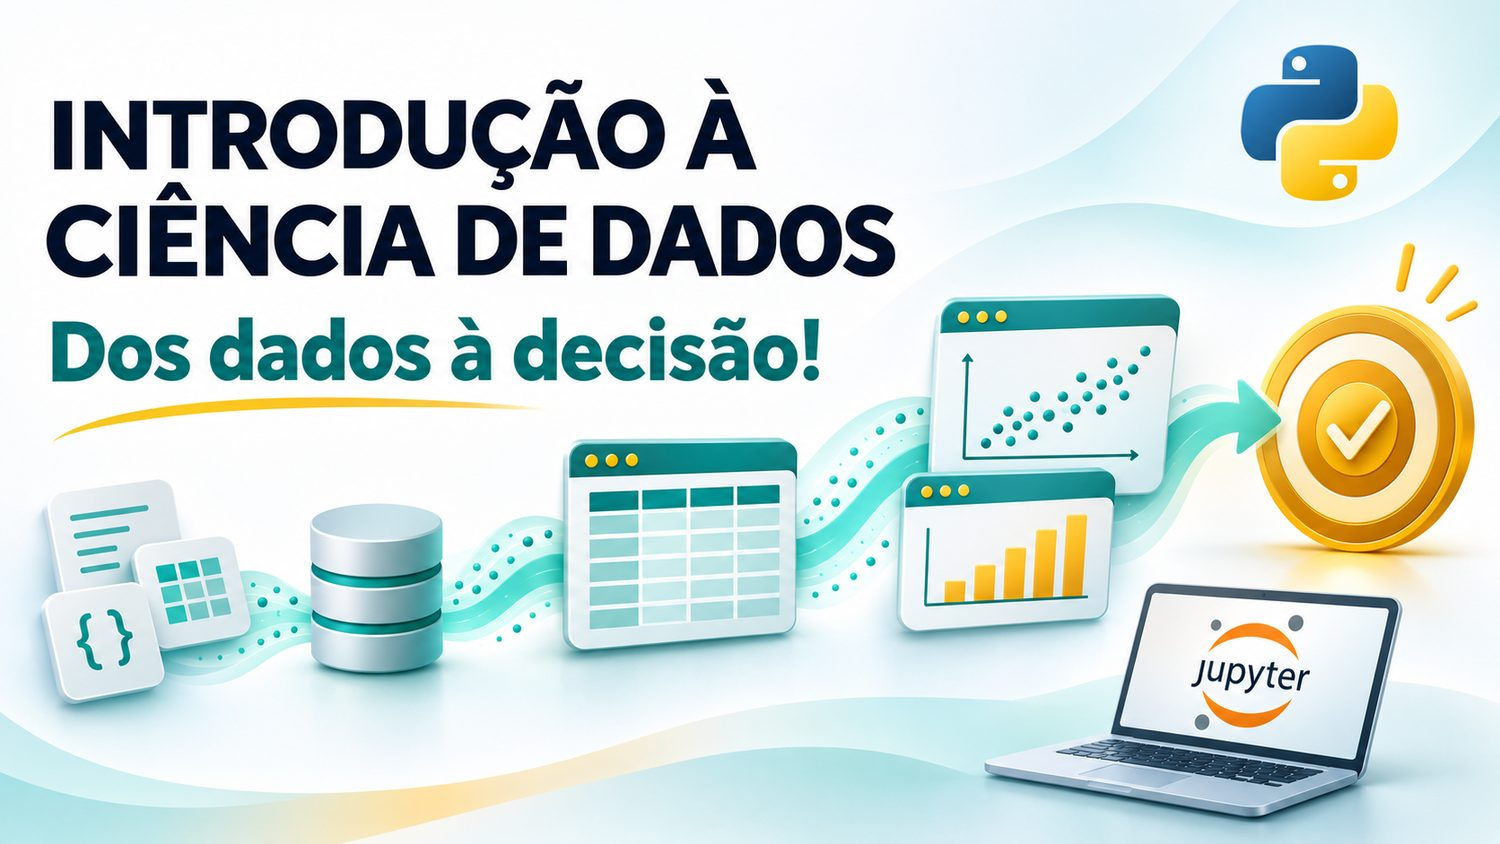

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_lineares/02_Regressao_Linear_Multipla.ipynb)

# Capítulo 2 – Regressão linear múltipla

Uma reta com um só atributo deixou por explicar a orientação do telhado, a sombra e a zona do país. A **regressão linear múltipla** usa vários atributos ao mesmo tempo: cada um tem o seu coeficiente, e a previsão é a soma das contribuições de todos. Este capítulo calcula-a de raiz de duas maneiras, ensina a ler os coeficientes e mostra os problemas mais comuns.

> **Objetivos:** escrever o modelo com vários atributos; calculá-lo de raiz pela equação normal e por descida do gradiente; interpretar um coeficiente «mantendo o resto constante»; incluir atributos nominais e ler os seus coeficientes; comparar a importância de atributos com coeficientes normalizados; reconhecer a colinearidade; usar o logaritmo quando os efeitos se multiplicam.

**Pré-requisitos:** capítulo 1, e os capítulos 4 e 5 do módulo 4 (escalas e codificação). As operações com matrizes estão em [NumPy](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_1_introducao/22_NumPy.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_instalacoes(n=1500, semente=61):
    """Gera instalações solares residenciais de uma empresa fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    potencia = rng.gamma(4.0, 1.1, n).clip(1.5, 12).round(1)
    zona = rng.choice(["norte", "centro", "sul"], n, p=[0.35, 0.4, 0.25])
    orientacao = rng.choice(["sul", "este", "oeste"], n, p=[0.55, 0.22, 0.23])
    inclinacao = rng.normal(28, 8, n).clip(5, 50).round()
    sombra = (rng.beta(1.2, 6, n) * 60).round()
    idade = rng.integers(0, 13, n)
    sol = pd.Series(zona).map({"norte": 1280, "centro": 1420, "sul": 1570}).to_numpy()              # kWh por kWp, por ano
    fator = (pd.Series(orientacao).map({"sul": 1.0, "este": 0.86, "oeste": 0.84}).to_numpy() * (1 - 0.00035 * (inclinacao - 32) ** 2)
             * (1 - 0.009 * sombra) * (1 - 0.006 * idade))
    producao = potencia * sol * fator * rng.normal(1, 0.05, n)
    return pd.DataFrame({"potencia_kwp": potencia, "zona": zona, "orientacao": orientacao, "inclinacao_graus": inclinacao,
                         "sombra_pct": sombra, "idade_anos": idade, "producao_kwh": producao.round(-1)})


instalacoes = gerar_instalacoes()
instalacoes.head()

,potencia_kwp,zona,orientacao,inclinacao_graus,sombra_pct,idade_anos,producao_kwh
0,3.0,centro,este,22.0,13.0,0,3280.0
1,1.5,sul,sul,34.0,27.0,7,1720.0
2,6.1,centro,sul,30.0,9.0,7,7850.0
3,3.0,centro,sul,28.0,2.0,7,3670.0
4,2.2,centro,sul,26.0,29.0,2,2260.0


## De uma reta a uma soma ponderada

> **previsão = b₀ + b₁ × atributo₁ + b₂ × atributo₂ + … + bₖ × atributoₖ**

- **b₀** é a ordenada na origem: a previsão quando todos os atributos valem zero.
- Cada **bⱼ** é o **coeficiente** de um atributo: quanto muda a previsão quando esse atributo aumenta uma unidade **e os outros ficam iguais**.

Com um atributo era uma reta; com dois, é um plano; com mais, já não se desenha, mas a conta é a mesma. O critério também: os coeficientes escolhidos são os que tornam mínima a soma dos quadrados dos resíduos.

Começamos com os quatro atributos numéricos.

In [3]:
from sklearn.model_selection import train_test_split

treino, teste = train_test_split(instalacoes, test_size=0.25, random_state=0)
numericas = ["potencia_kwp", "inclinacao_graus", "sombra_pct", "idade_anos"]
y, y_teste = treino["producao_kwh"].to_numpy(), teste["producao_kwh"].to_numpy()

## Calcular de raiz (1): a equação normal

Para escrever o modelo de forma compacta, juntam-se os atributos numa tabela **X**, com uma linha por instalação, e acrescenta-se uma **coluna de uns**, que serve para a ordenada na origem. As previsões de todas as instalações são então um único produto: `X @ b`.

Os coeficientes que minimizam a soma dos quadrados são a solução de um sistema de equações, a **equação normal**:

> **(Xᵀ X) b = Xᵀ y**

É a generalização das fórmulas do capítulo 1: `Xᵀ X` faz o papel da variância, e `Xᵀ y` o da covariância. O NumPy resolve o sistema numa linha.

In [4]:
def com_coluna_de_uns(tabela):
    """Acrescenta a coluna de uns que representa a ordenada na origem."""
    tabela = np.asarray(tabela, dtype=float)
    return np.column_stack([np.ones(len(tabela)), tabela])


def minimos_quadrados(X, y):
    """Resolve a equação normal (XᵀX) b = Xᵀy."""
    return np.linalg.solve(X.T @ X, X.T @ y)


X = com_coluna_de_uns(treino[numericas])
b = minimos_quadrados(X, y)
coeficientes = pd.Series(b, index=["ordenada na origem"] + numericas)
print(coeficientes.round(1))

ordenada na origem     407.8
potencia_kwp          1123.5
inclinacao_graus        12.1
sombra_pct             -53.5
idade_anos             -34.6
dtype: float64


In [5]:
from sklearn.linear_model import LinearRegression

oficial = LinearRegression().fit(treino[numericas], y)
print("scikit-learn:", np.round(np.append(oficial.intercept_, oficial.coef_), 1))
print("A nossa:     ", b.round(1))

scikit-learn: [ 407.8 1123.5   12.1  -53.5  -34.6]
A nossa:      [ 407.8 1123.5   12.1  -53.5  -34.6]


Os resultados são iguais. Prever é uma multiplicação e uma soma:

In [6]:
exemplo = pd.DataFrame([{"potencia_kwp": 5.0, "inclinacao_graus": 30, "sombra_pct": 10, "idade_anos": 3}])
parcelas = pd.Series(b[1:] * exemplo.iloc[0].to_numpy(), index=numericas)
print(f"ordenada na origem  {b[0]:>9.0f}")
for nome, valor in parcelas.items():
    print(f"{nome:<19} {valor:>9.0f}   ({coeficientes[nome]:.1f} × {exemplo.iloc[0][nome]:g})")
print(f"{'previsão':<19} {b[0] + parcelas.sum():>9.0f} kWh")

ordenada na origem        408
potencia_kwp             5617   (1123.5 × 5)
inclinacao_graus          363   (12.1 × 30)
sombra_pct               -535   (-53.5 × 10)
idade_anos               -104   (-34.6 × 3)
previsão                 5750 kWh


A previsão **decompõe-se** em parcelas, uma por atributo. Pode dizer-se ao cliente quanto da produção prevista vem da potência e quanto se perde com a sombra. É a principal razão para se usar um modelo linear: lê-se.

## Calcular de raiz (2): descer a encosta

A equação normal dá a resposta de uma vez. Há outra forma de lá chegar, que serve para quase todos os modelos de aprendizagem automática, incluindo o do próximo capítulo: a **descida do gradiente**.

A ideia: o erro, visto como função dos coeficientes, é uma taça (capítulo 1). Começa-se num ponto qualquer e dão-se passos **no sentido em que o erro desce mais depressa**, até chegar ao fundo.

1. Começar com todos os coeficientes a zero.
2. Calcular o **gradiente**: para cada coeficiente, quanto muda o erro se ele aumentar um pouco.
3. Mover cada coeficiente um pequeno passo no sentido contrário ao do gradiente.
4. Repetir.

Para o erro quadrático médio, o gradiente tem uma forma simples: `(2 / n) × Xᵀ (X b − y)`, ou seja, os resíduos projetados em cada atributo.

Um pormenor prático: a descida do gradiente funciona mal com atributos em escalas muito diferentes, porque a taça fica muito alongada. Normalizamos primeiro.

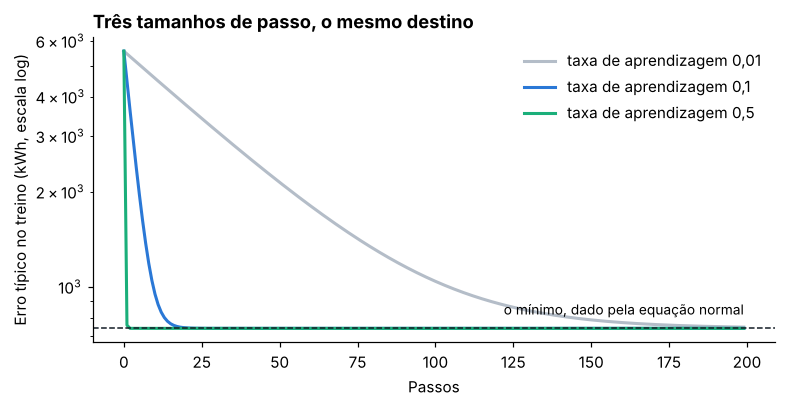

In [7]:
media, desvio = treino[numericas].mean().to_numpy(), treino[numericas].std().to_numpy()
Z = com_coluna_de_uns((treino[numericas].to_numpy() - media) / desvio)


def descida_do_gradiente(X, y, taxa=0.1, passos=200):
    """Minimiza o erro quadrático médio. Devolve os coeficientes e o erro em cada passo."""
    b = np.zeros(X.shape[1])
    historico = []
    for _ in range(passos):
        residuos = X @ b - y
        historico.append(float(np.mean(residuos ** 2)))
        gradiente = 2 / len(y) * X.T @ residuos
        b = b - taxa * gradiente                            # um passo no sentido em que o erro desce
    return b, historico


fig, ax = plt.subplots(figsize=(8, 3.6))
for taxa, cor in [(0.01, CINZA), (0.1, AZUL), (0.5, VERDE)]:
    _, historico = descida_do_gradiente(Z, y, taxa=taxa)
    ax.plot(np.sqrt(historico), color=cor, lw=2, label=f"taxa de aprendizagem {taxa}".replace(".", ","))
minimo = np.sqrt(np.mean((Z @ minimos_quadrados(Z, y) - y) ** 2))
ax.axhline(minimo, color=TINTA, ls="--", lw=1)
ax.text(199, minimo * 1.08, "o mínimo, dado pela equação normal", ha="right", va="bottom", fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("Passos")
ax.set_ylabel("Erro típico no treino (kWh, escala log)")
ax.set_title("Três tamanhos de passo, o mesmo destino")
ax.legend(frameon=False)
plt.show()

A **taxa de aprendizagem** é o tamanho do passo. Com passos pequenos chega-se devagar; com passos maiores, mais depressa. Com passos grandes de mais, salta-se de um lado para o outro da taça e o erro **aumenta** em vez de diminuir (experimenta com uma taxa de 1,1).

In [8]:
b_gradiente, _ = descida_do_gradiente(Z, y, taxa=0.5, passos=200)
print("Descida do gradiente:", b_gradiente.round(1))
print("Equação normal:      ", minimos_quadrados(Z, y).round(1))

Descida do gradiente: [4970.7 2364.6   93.2 -408.1 -132.7]
Equação normal:       [4970.7 2364.6   93.2 -408.1 -132.7]


As duas chegam aos mesmos coeficientes. (São diferentes dos de há pouco porque os atributos estão normalizados; voltaremos a isso.)

| | Equação normal | Descida do gradiente |
| --- | --- | --- |
| Como | Resolve um sistema, de uma vez | Aproxima-se por passos |
| Hiperparâmetros | Nenhum | Taxa de aprendizagem, número de passos |
| Custo | Cresce depressa com o número de atributos | Serve para milhões de linhas e de atributos |
| Serve para | Regressão linear | Quase todos os modelos, incluindo redes neuronais |

Há mais sobre este método em [Otimização e grupos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_08_Otimizacao_Grupos.ipynb).

## Ler um coeficiente: «mantendo o resto constante»

No capítulo 1, a reta com a sombra como único atributo deu um declive (exercício 2). Comparamos com o coeficiente da sombra no modelo com os quatro atributos, e fazemos o mesmo para a idade.

In [9]:
linhas = {}
for nome in ["sombra_pct", "idade_anos"]:
    sozinho = LinearRegression().fit(treino[[nome]], y).coef_[0]
    linhas[nome] = {"sozinho (reta simples)": sozinho, "com os outros atributos": coeficientes[nome]}
pd.DataFrame(linhas).T.round(1)

,sozinho (reta simples),com os outros atributos
sombra_pct,-59.2,-53.5
idade_anos,4.5,-34.6


O coeficiente da sombra quase não muda. O da idade **muda de sinal**: sozinha, a idade parece não fazer mal nenhum à produção, ou até ajudar; com a potência no modelo, cada ano tira algumas dezenas de kWh.

A explicação está nos dados: as instalações mais antigas desta empresa são, em média, um pouco **maiores**. A reta simples comparava instalações antigas e grandes com instalações novas e pequenas, e atribuía à idade o efeito do tamanho. O modelo múltiplo compara instalações **com a mesma potência**, e aí vê-se a degradação dos painéis.

> O coeficiente de um atributo num modelo múltiplo é o seu efeito médio **entre observações iguais em todos os outros atributos do modelo**.

É a mesma ideia da variável de confusão do módulo 1: juntar a variável de confusão ao modelo «controla» o seu efeito. Com dois limites: só se controla o que está **no modelo**, e o resultado continua a ser uma associação. Uma variável de confusão que não foi medida continua a baralhar os coeficientes.

## Atributos nominais

A zona e a orientação são categorias. Entram no modelo pela codificação *one-hot* do módulo 4, com um pormenor: retira-se **uma categoria de cada atributo**, que passa a ser a **referência**.

Com a coluna de uns no modelo, as três colunas `zona_norte`, `zona_centro` e `zona_sul` somariam sempre 1, e haveria infinitas combinações de coeficientes a dar as mesmas previsões. Retirando uma, o problema desaparece.

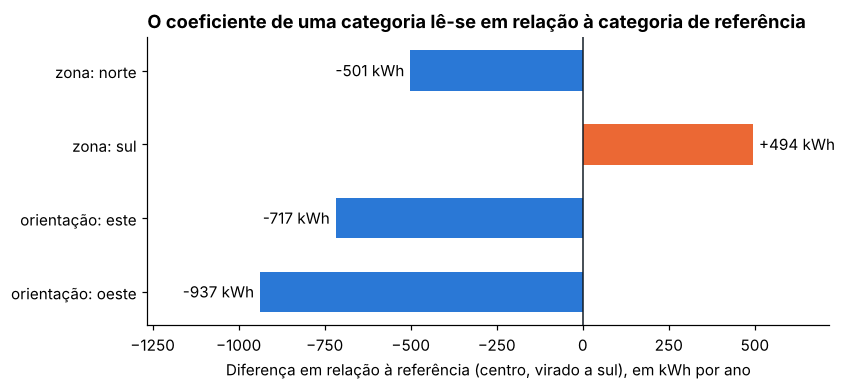

In [10]:
def preparar(dados):
    """Atributos numéricos mais as categorias em colunas de 0 e 1 (referências: zona centro, orientação sul)."""
    tabela = dados[numericas].copy()
    for zona in ["norte", "sul"]:
        tabela[f"zona_{zona}"] = (dados["zona"] == zona).astype(float)
    for orientacao in ["este", "oeste"]:
        tabela[f"orientacao_{orientacao}"] = (dados["orientacao"] == orientacao).astype(float)
    return tabela


X_treino, X_teste = preparar(treino), preparar(teste)
completo = LinearRegression().fit(X_treino, y)
coef_completo = pd.Series(completo.coef_, index=X_treino.columns)

fig, ax = plt.subplots(figsize=(8, 3.4))
categorias = coef_completo[["zona_norte", "zona_sul", "orientacao_este", "orientacao_oeste"]]
barras = ax.barh(["zona: norte", "zona: sul", "orientação: este", "orientação: oeste"], categorias, color=[LARANJA if v > 0 else AZUL for v in categorias], height=0.55)
ax.bar_label(barras, fmt="%+.0f kWh", padding=4)
ax.axvline(0, color=TINTA, lw=1)
ax.invert_yaxis()
ax.set_xlim(categorias.min() * 1.35, categorias.max() * 1.45)
ax.set_xlabel("Diferença em relação à referência (centro, virado a sul), em kWh por ano")
ax.set_title("O coeficiente de uma categoria lê-se em relação à categoria de referência")
plt.show()

Cada coeficiente é a diferença média em relação à **referência**, para instalações iguais em tudo o resto. Uma instalação no norte produz cerca de 500 kWh a menos do que uma igual no centro; um telhado virado a oeste, perto de 900 kWh a menos do que um virado a sul.

Mudar a categoria de referência muda os coeficientes e **não muda as previsões**: é a mesma informação vista de outro ponto.

## Que atributo conta mais?

Os coeficientes não se podem comparar diretamente: estão em unidades diferentes. O da potência é em kWh por kWp, o da sombra em kWh por ponto percentual. Um coeficiente pequeno pode pertencer a um atributo que varia muito.

Para os comparar, ajusta-se o modelo com os atributos numéricos **normalizados**. Cada coeficiente passa a ser o efeito de **um desvio padrão** desse atributo.

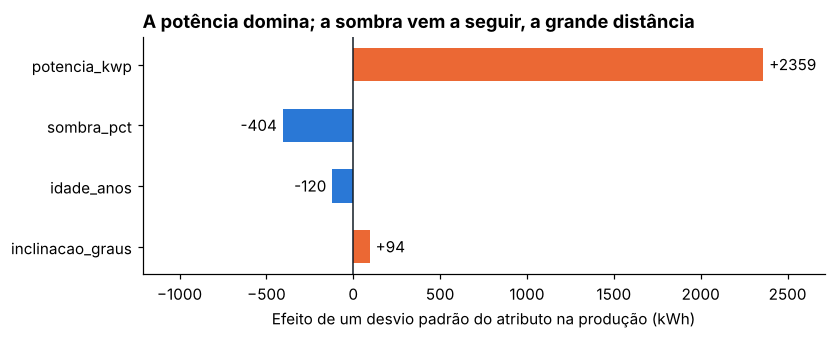

In [11]:
escalas = X_treino[numericas].std()
normalizados = (coef_completo[numericas] * escalas).sort_values(key=abs)

fig, ax = plt.subplots(figsize=(8, 2.8))
barras = ax.barh(normalizados.index, normalizados, color=[LARANJA if v > 0 else AZUL for v in normalizados], height=0.55)
ax.bar_label(barras, fmt="%+.0f", padding=4)
ax.axvline(0, color=TINTA, lw=1)
ax.set_xlim(normalizados.min() * 3, normalizados.max() * 1.15)
ax.set_xlabel("Efeito de um desvio padrão do atributo na produção (kWh)")
ax.set_title("A potência domina; a sombra vem a seguir, a grande distância")
plt.show()

A potência conta muito mais do que tudo o resto: é o que distingue uma instalação pequena de uma grande. A sombra vem a seguir. A inclinação e a idade têm efeitos pequenos.

«Conta mais» quer dizer, aqui, «explica mais das diferenças **entre as instalações destes dados**». Num conjunto de instalações todas do mesmo tamanho, a potência não explicaria nada.

## Quanto melhorou?

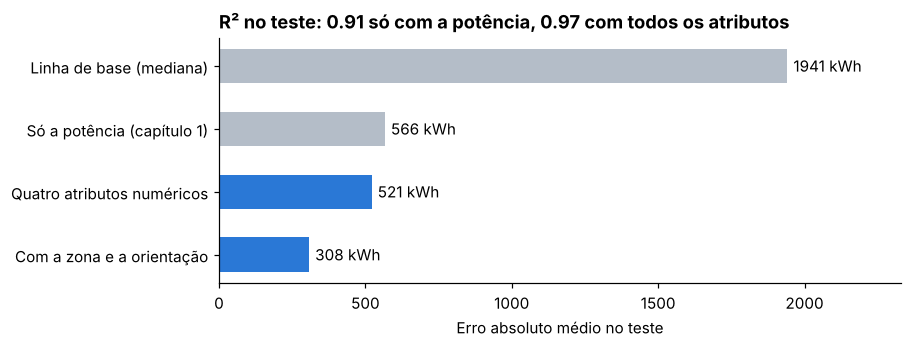

In [12]:
def mae(modelo, X):
    return np.abs(y_teste - modelo.predict(X)).mean()


so_potencia = LinearRegression().fit(treino[["potencia_kwp"]], y)
so_numericas = LinearRegression().fit(treino[numericas], y)
resultados = {"Linha de base (mediana)": np.abs(y_teste - np.median(y)).mean(), "Só a potência (capítulo 1)": mae(so_potencia, teste[["potencia_kwp"]]),
              "Quatro atributos numéricos": mae(so_numericas, teste[numericas]), "Com a zona e a orientação": mae(completo, X_teste)}

fig, ax = plt.subplots(figsize=(8, 2.9))
barras = ax.barh(list(resultados), list(resultados.values()), color=[CINZA, CINZA, AZUL, AZUL], height=0.55)
ax.bar_label(barras, fmt="%.0f kWh", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(resultados.values()) * 1.2)
ax.set_xlabel("Erro absoluto médio no teste")
ax.set_title(f"R² no teste: {so_potencia.score(teste[['potencia_kwp']], y_teste):.2f} só com a potência, {completo.score(X_teste, y_teste):.2f} com todos os atributos")
plt.show()

Cada grupo de atributos baixa o erro. Com todos, o modelo erra cerca de 300 kWh, quase metade do erro da reta simples.

Os resíduos dizem se ainda há alguma coisa por aproveitar.

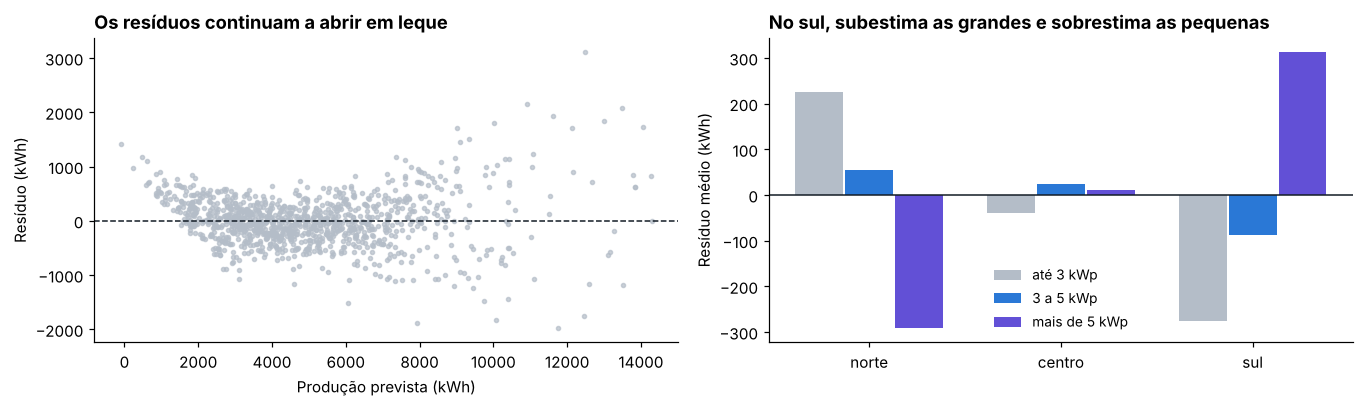

In [13]:
residuos = y - completo.predict(X_treino)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax1.scatter(completo.predict(X_treino), residuos, s=7, color=CINZA, alpha=0.7)
ax1.axhline(0, color=TINTA, lw=1, ls="--")
ax1.set_xlabel("Produção prevista (kWh)")
ax1.set_ylabel("Resíduo (kWh)")
ax1.set_title("Os resíduos continuam a abrir em leque")
tamanho = pd.cut(treino["potencia_kwp"], [0, 3, 5, 12], labels=["até 3 kWp", "3 a 5 kWp", "mais de 5 kWp"])
tabela = pd.Series(residuos, index=treino.index).groupby([treino["zona"], tamanho], observed=True).mean().unstack()
posicoes = np.arange(3)
for i, (coluna, cor) in enumerate(zip(tabela.columns, [CINZA, AZUL, VIOLETA])):
    ax2.bar(posicoes + (i - 1) * 0.26, tabela.loc[["norte", "centro", "sul"], coluna], 0.25, color=cor, label=coluna)
ax2.axhline(0, color=TINTA, lw=1)
ax2.set_xticks(posicoes, ["norte", "centro", "sul"])
ax2.set_ylabel("Resíduo médio (kWh)")
ax2.set_title("No sul, subestima as grandes e sobrestima as pequenas")
ax2.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

O leque continua lá, e o gráfico da direita mostra porquê. O modelo dá ao sul um bónus **fixo**, igual para todas as instalações. Mas o sol a mais do sul vale tanto mais quanto maior for a instalação: nas grandes, o bónus fixo é pouco; nas pequenas, é de mais. No norte acontece o inverso.

O modelo **soma** efeitos que na realidade se **multiplicam**: a produção é a potência **vezes** o sol da zona **vezes** as perdas da orientação e da sombra.

## Quando os efeitos se multiplicam: o logaritmo

O logaritmo transforma produtos em somas: log(a × b) = log(a) + log(b). Se a produção é um produto de fatores, o **logaritmo da produção** é uma soma, que é exatamente o que um modelo linear sabe representar.

Ajustamos o mesmo modelo ao logaritmo da produção, com o logaritmo da potência.

In [14]:
def preparar_log(dados):
    return preparar(dados).assign(potencia_kwp=np.log(dados["potencia_kwp"])).rename(columns={"potencia_kwp": "log_potencia"})


modelo_log = LinearRegression().fit(preparar_log(treino), np.log(y))
previsto_log = np.exp(modelo_log.predict(preparar_log(teste)))                    # de volta a kWh
mae_log = np.abs(y_teste - previsto_log).mean()
print(f"Erro absoluto médio no teste: {mae(completo, X_teste):.0f} kWh (modelo aditivo) → {mae_log:.0f} kWh (modelo em logaritmos)")

efeitos = pd.Series(modelo_log.coef_, index=preparar_log(treino).columns)
pd.DataFrame({"coeficiente": efeitos.round(4), "efeito na produção": [f"{np.exp(c) - 1:+.1%}" if nome != "log_potencia" else f"+1% de potência → {c:+.2f}%" for nome, c in efeitos.items()]})

Erro absoluto médio no teste: 308 kWh (modelo aditivo) → 215 kWh (modelo em logaritmos)


,coeficiente,efeito na produção
log_potencia,0.9969,+1% de potência → +1.00%
inclinacao_graus,0.0028,+0.3%
sombra_pct,-0.0107,-1.1%
idade_anos,-0.0066,-0.7%
zona_norte,-0.1055,-10.0%
zona_sul,0.0912,+9.5%
orientacao_este,-0.1428,-13.3%
orientacao_oeste,-0.1780,-16.3%


O erro desce mais um terço, sem acrescentar nenhum atributo: só mudou a **forma** do modelo.

Os coeficientes passam a ler-se em **percentagens**:

- um coeficiente pequeno, como o da sombra, é aproximadamente a variação relativa: cada ponto de sombra a mais tira cerca de 1% à produção;
- para as categorias, o efeito exato é exp(coeficiente) − 1: um telhado virado a oeste produz cerca de 16% menos do que um virado a sul, **qualquer que seja o tamanho**;
- o coeficiente do logaritmo da potência, muito perto de 1, diz que 1% a mais de potência dá 1% a mais de produção: a produção é proporcional à potência.

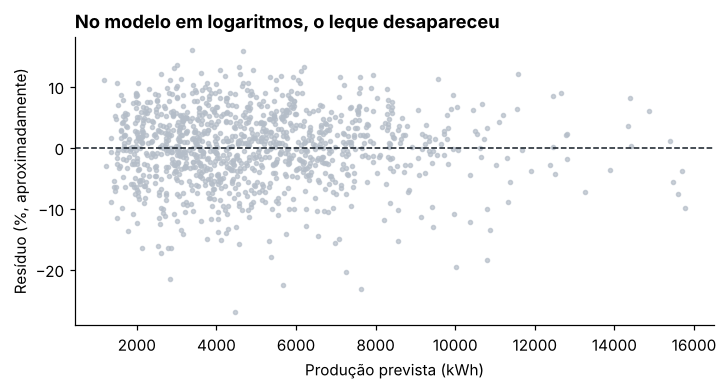

In [15]:
residuos_log = np.log(y) - modelo_log.predict(preparar_log(treino))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.scatter(np.exp(modelo_log.predict(preparar_log(treino))), residuos_log * 100, s=7, color=CINZA, alpha=0.7)
ax.axhline(0, color=TINTA, lw=1, ls="--")
ax.set_xlabel("Produção prevista (kWh)")
ax.set_ylabel("Resíduo (%, aproximadamente)")
ax.set_title("No modelo em logaritmos, o leque desapareceu")
plt.show()

Os resíduos têm agora a mesma dispersão em toda a parte, cerca de 6%, e não mostram padrão. O modelo aproveitou o que os atributos tinham para dar; o que resta é o que nenhum deles capta (um ano com mais nuvens, painéis sujos).

A transformação não se escolhe por tentativas às cegas: escolhe-se porque os **resíduos** mostraram um erro proporcional e porque o conhecimento do problema diz que os fatores se multiplicam.

## Colinearidade: quando dois atributos dizem o mesmo

Suponhamos que a empresa regista também o número de painéis. Cada painel tem cerca de 0,4 kWp, e por isso esta coluna é quase uma cópia da potência.

Correlação entre a potência e o número de painéis: 0.992


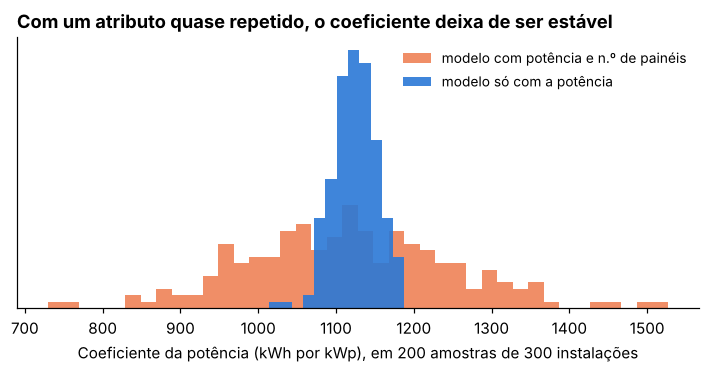

In [16]:
rng = np.random.default_rng(1)
com_paineis = treino.assign(n_paineis=(treino["potencia_kwp"] / 0.4 + rng.normal(0, 0.6, len(treino))).round())
print(f"Correlação entre a potência e o número de painéis: {com_paineis['potencia_kwp'].corr(com_paineis['n_paineis']):.3f}")

estimativas = {"sem n_paineis": [], "com n_paineis": []}
for semente in range(200):                                           # 200 amostras de 300 instalações
    amostra = com_paineis.sample(300, random_state=semente)
    estimativas["sem n_paineis"].append(LinearRegression().fit(amostra[numericas], amostra["producao_kwh"]).coef_[0])
    estimativas["com n_paineis"].append(LinearRegression().fit(amostra[numericas + ["n_paineis"]], amostra["producao_kwh"]).coef_[0])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(estimativas["com n_paineis"], bins=40, color=LARANJA, alpha=0.75, label="modelo com potência e n.º de painéis")
ax.hist(estimativas["sem n_paineis"], bins=12, color=AZUL, alpha=0.9, label="modelo só com a potência")
ax.set_xlabel("Coeficiente da potência (kWh por kWp), em 200 amostras de 300 instalações")
ax.set_yticks([])
ax.set_title("Com um atributo quase repetido, o coeficiente deixa de ser estável")
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.show()

Sem a coluna repetida, o coeficiente da potência anda sempre perto de 1 100. Com ela, varia de amostra para amostra entre menos de 900 e mais de 1 350. O modelo não consegue decidir como repartir o efeito entre duas colunas que sobem e descem juntas: «mais potência, mantendo o número de painéis constante» é uma situação que quase não existe nos dados.

| A colinearidade | |
| --- | --- |
| **Não estraga** | As previsões, enquanto os casos novos tiverem a mesma relação entre as colunas |
| **Estraga** | A interpretação dos coeficientes, que ficam instáveis e podem mudar de sinal |
| **Deteta-se** | Pela matriz de correlações entre atributos; por coeficientes que mudam muito quando se junta ou retira uma coluna |
| **Resolve-se** | Retirando uma das colunas, juntando-as numa só, ou regularizando (capítulo 4) |

## Os pressupostos, em resumo

Uma regressão linear dá sempre coeficientes. Para os poder **ler** com confiança, convém verificar:

| Pressuposto | Como se verifica | Se falhar |
| --- | --- | --- |
| A relação é **linear e aditiva** | Resíduos sem curva e sem padrão por grupo | Transformar (logaritmo), criar atributos (quadrado, interação) |
| Os erros têm **dispersão constante** | Resíduos sem forma de leque | Transformar o alvo |
| As observações são **independentes** | Conhecimento dos dados (várias linhas da mesma casa? dados no tempo?) | Dividir por grupos ou no tempo (módulo 4) |
| Não há **valores extremos** a dominar | Gráficos; refazer sem os pontos suspeitos | Investigar, corrigir ou usar um método robusto |
| Os atributos não são **quase repetidos** | Correlações entre atributos | Retirar, combinar ou regularizar |

Para **prever**, o que conta é o erro no teste. Para **interpretar**, contam os pressupostos.

## Exercícios

### `Exercício 1` – Uma previsão à mão

Um modelo tem os coeficientes: ordenada na origem 200; potência 1 100 (por kWp); sombra −50 (por ponto percentual); zona norte −500; zona sul +500 (referência: centro). Calcula a previsão para (a) 4 kWp, 10% de sombra, no centro; (b) 4 kWp, 10% de sombra, no sul; (c) 6 kWp, 0% de sombra, no norte.

<details>
<summary><b>Ver uma solução possível</b></summary>

- (a) 200 + 1 100 × 4 − 50 × 10 = **4 100 kWh**.
- (b) O mesmo, mais o coeficiente do sul: 4 100 + 500 = **4 600 kWh**.
- (c) 200 + 1 100 × 6 − 0 − 500 = **6 300 kWh**.

Para o centro não se soma nada: é a categoria de referência, e o seu efeito está na ordenada na origem.

</details>

### `Exercício 2` – A taxa de aprendizagem

Corre a função `descida_do_gradiente` com as taxas 0,9, 1,0 e 1,1 e 30 passos. Imprime o erro nos passos 0, 10, 20 e 29. O que acontece, e porquê?

In [17]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for taxa in [0.9, 1.0, 1.1]:
    _, h = descida_do_gradiente(Z, y, taxa=taxa, passos=30)
    print(f"taxa {taxa}: " + " → ".join(f"{np.sqrt(h[i]):,.0f}".replace(",", " ") for i in [0, 10, 20, 29]))
```

Com 0,9 o erro desce, aos solavancos. Com valores maiores, cada passo vai parar ao outro lado da taça, mais acima do que estava, e o erro **cresce** sem parar: o método diverge. A taxa de aprendizagem tem de ser suficientemente pequena para o passo não saltar o fundo; o limite depende da escala dos atributos, e é mais uma razão para os normalizar.

</details>

### `Exercício 3` – Mudar a referência

Refaz o modelo completo usando o **norte** e a orientação **este** como categorias de referência. Os coeficientes mudam? E as previsões no teste?

In [18]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def preparar_b(dados):
    tabela = dados[numericas].copy()
    for zona in ["centro", "sul"]:
        tabela[f"zona_{zona}"] = (dados["zona"] == zona).astype(float)
    for orientacao in ["sul", "oeste"]:
        tabela[f"orientacao_{orientacao}"] = (dados["orientacao"] == orientacao).astype(float)
    return tabela


outro = LinearRegression().fit(preparar_b(treino), y)
print(pd.Series(outro.coef_, index=preparar_b(treino).columns).round(0)[4:])
print("Maior diferença entre as previsões dos dois modelos:", np.abs(outro.predict(preparar_b(teste)) - completo.predict(X_teste)).max().round(6))
```

Os coeficientes das categorias mudam (agora medem a diferença em relação ao norte e ao este), e a ordenada na origem também. Os dos atributos numéricos ficam iguais, e as previsões são idênticas. A escolha da referência é uma questão de leitura: convém escolher a categoria mais frequente ou a que serve de termo de comparação natural.

</details>

### `Exercício 4` – Um atributo ao quadrado

A produção é máxima com uma inclinação perto dos 32 graus e desce para os dois lados: a relação é uma curva, e um coeficiente único não a representa. Acrescenta ao modelo em logaritmos a coluna `(inclinacao_graus − 32)²`. O erro no teste melhora? Que sinal tem o novo coeficiente, e o que acontece ao coeficiente da inclinação?

In [19]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def preparar_curva(dados):
    return preparar_log(dados).assign(inclinacao_quadrado=(dados["inclinacao_graus"] - 32) ** 2)


curva = LinearRegression().fit(preparar_curva(treino), np.log(y))
print(f"MAE no teste: {mae_log:.0f} → {np.abs(y_teste - np.exp(curva.predict(preparar_curva(teste)))).mean():.0f} kWh")
print(pd.Series(curva.coef_, index=preparar_curva(treino).columns)[["inclinacao_graus", "inclinacao_quadrado"]].round(5))
```

O erro baixa um pouco. O coeficiente do quadrado é negativo: a produção desce à medida que a inclinação se afasta dos 32 graus, para qualquer dos lados. O coeficiente da inclinação fica perto de zero, porque a subida que ele descrevia era só a metade esquerda da curva. Um modelo «linear» é linear **nos coeficientes**: pode perfeitamente representar curvas, desde que lhe demos as colunas certas.

</details>

## Verifica o que aprendeste

- [ ] Sei escrever um modelo linear com vários atributos.
- [ ] Sei calculá-lo pela equação normal e por descida do gradiente.
- [ ] Sei o que é a taxa de aprendizagem.
- [ ] Sei interpretar um coeficiente «mantendo o resto constante».
- [ ] Sei ler o coeficiente de uma categoria em relação à referência.
- [ ] Sei comparar atributos com coeficientes normalizados.
- [ ] Sei reconhecer nos resíduos efeitos que se multiplicam, e usar o logaritmo.
- [ ] Sei o que é a colinearidade e o que ela estraga.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/linear_model.html
- https://en.wikipedia.org/wiki/Linear_regression
- https://en.wikipedia.org/wiki/Gradient_descent
- https://en.wikipedia.org/wiki/Multicollinearity